# Use case

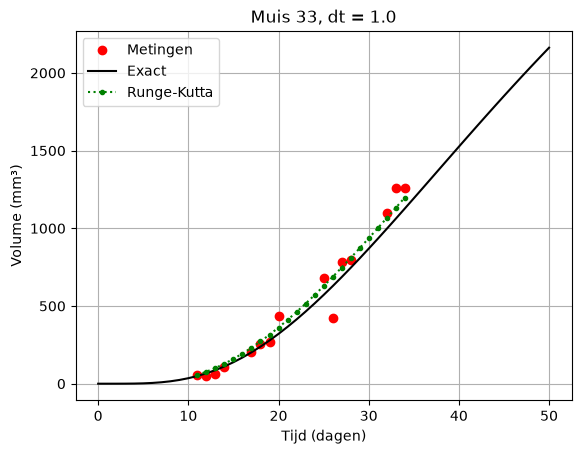

In [1]:
from package.models import *
from package.test_runge_kutta import runge_kutta  # TODO de functie voor runge_kutta uit test_runge_kutta halen
from package.random_search import random_search
from package.model_comparison import *

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
data = pd.read_csv("test_data/LM2-4LUC.txt", sep="\t")

muis33 = data[data["ID"] == 33]
muis34 = data[data["ID"] == 34]
muis35 = data[data["ID"] == 35]

In [4]:
def plot_test_data(data, marker_size = None, title = None, label = None, color = None):
    plt.scatter(x= data["Time"], y = data["Observation"], s = marker_size, label = label, c = color)
    plt.ylabel("Volume ($mm^3$)")
    plt.xlabel("Time (days) after implantation")
    plt.grid(visible = True)
    plt.ylim(bottom=0)
    plt.axvline(0.0, color='k') # maakt een verticale zwarte lijn op de x = 0
    plt.title(title)

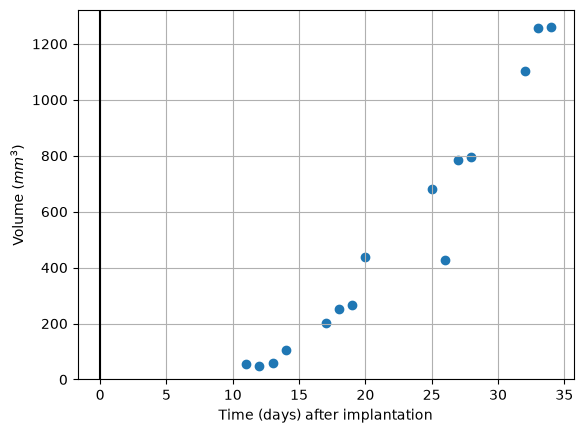

In [5]:
plot_test_data(muis33)

In [6]:
t_data = muis33["Time"].values
V_data = muis33["Observation"].values

mse, params_random = random_search(t_data, V_data, bertalanffy, dt = 1)
print(mse)
print(params_random)

5599.757925023659
{'alpha': 1.230129109784151, 'beta': 0.041292209261823205}


BERTALANFFY
gevonden params: {'alpha': 1.2363, 'beta': 0.0421}
scores: MSE = 5599.78, BIC = 137.58, AIC = 135.46, AICc = 137.64

GOMPERTZ
gevonden params: {'alpha': 0.4645, 'beta': 0.0556}
scores: MSE = 5782.12, BIC = 138.06, AIC = 135.94, AICc = 138.12

LOGISTIC
gevonden params: {'alpha': 0.2036, 'beta': 1500.1195}
scores: MSE = 7186.77, BIC = 141.32, AIC = 139.20, AICc = 141.38

EXPONENTIAL
gevonden params: {'c': 0.1408}
scores: MSE = 18755.67, BIC = 153.00, AIC = 151.59, AICc = 152.59

MENDELSOHN
gevonden params: {'c': 1.7953, 'd': 0.5534}
scores: MSE = 5564.57, BIC = 137.49, AIC = 135.36, AICc = 137.54



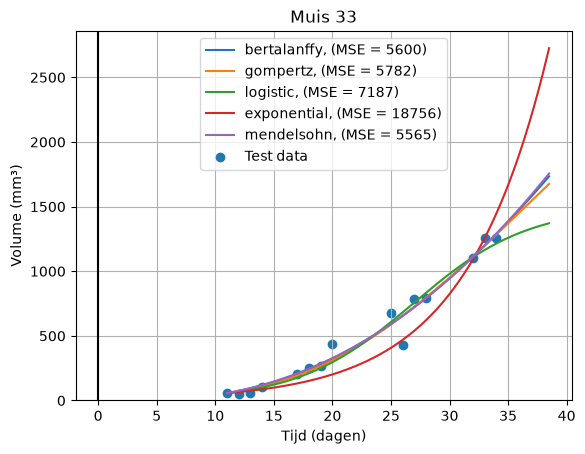

In [ ]:
dt = .1
t_start = t_data[0]
V_start = V_data[0]
n_steps = 275


for model in [bertalanffy, gompertz, logistic, exponential, mendelsohn]:
    mse, params = random_search(t_data, V_data, model, dt = 1)
    ts, Vs = runge_kutta(model, t_start, V_start, dt, n_steps, **params)
    plt.plot(ts, Vs, label=f"{model.__name__}, (MSE = {mse:.0f})")

    print(model.__name__.upper())
    # parameters afronden zodat het ietsjes netter lijkt
    params_rounded = {param : round(value, ndigits=4) for param, value in params.items()}
    print(f"gevonden params: {params_rounded}")

    n = len(t_data)
    bic = BIC(mse, n, model)
    aic = AIC(mse, n, model)
    aicc = AICc(mse, n, model)
    print(f"scores: MSE = {mse:.2f}, BIC = {bic:.2f}, AIC = {aic:.2f}, AICc = {aicc:.2f}")
    print()


plot_test_data(muis33, label = "Test data")

plt.xlabel("Tijd (dagen)")
plt.ylabel("Volume (mm³)")
plt.title("Muis 33")
plt.grid(True)
plt.legend()
plt.show()